<a href="https://colab.research.google.com/github/Alvin-Kyalo/SemProject_MLEngine/blob/main/MobileNetV2_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MobileNetV2 — Final ML Engine
## Dog Breed Identification System

This notebook contains the **final ML engine** of the Dog Breed Identification System.

**Approach:** Transfer learning with **MobileNetV2** (pre-trained on ImageNet), fine-tuned on the
Kaggle *Dog Breed Identification* dataset (120 breeds, 10,222 labelled images).

**Why MobileNetV2:** it gave the best accuracy of the three approaches we tested (see the comparison
at the end) while being small and fast enough to run **on-device** in the Android app via TensorFlow Lite.

**Pipeline**
1. Download the dataset from Kaggle
2. Stratified 70 / 15 / 15 train / validation / test split
3. Data augmentation (flip, rotation, zoom)
4. Stage 1 — train a new 120-class head on a frozen MobileNetV2 base
5. Stage 2 — fine-tune the top 30 layers of the base with a low learning rate
6. Evaluate on the held-out test set (accuracy, macro precision / recall / F1)
7. Inference engine: top-5 predictions + low-confidence safeguard
8. Export to TensorFlow Lite (`mobilenet_v2.tflite` + `labels.txt`) for the Android app

> Run on Google Colab with a **GPU runtime** (Runtime → Change runtime type → T4 GPU).

## 1. Download the dataset
Upload your `kaggle.json` API token when asked. You must have accepted the competition rules on Kaggle.

In [1]:
from google.colab import files
files.upload()  # choose kaggle.json

!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle competitions download -c dog-breed-identification
!mkdir -p data/raw && unzip -q -o dog-breed-identification.zip -d data/raw
!ls data/raw

Saving kaggle.json to kaggle.json
100% 691M/691M [00:18<00:00, 39.9MB/s]

labels.csv  sample_submission.csv  test  train


## 2. Imports and configuration

In [2]:
import json, time
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

ARCH = "mobilenet_v2"
DATA_DIR, IMG, BATCH = "data/raw", 224, 32
AUTOTUNE = tf.data.AUTOTUNE
tf.random.set_seed(42)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Load labels and split the data
Stratified split so every breed appears in train, validation and test in the same proportions.

In [3]:
df = pd.read_csv(f"{DATA_DIR}/labels.csv")
df["path"] = DATA_DIR + "/train/" + df["id"] + ".jpg"
class_names = sorted(df.breed.unique())                 # 120 breeds
df["y"] = df.breed.map({b: i for i, b in enumerate(class_names)})

train_df, tmp = train_test_split(df, test_size=0.30, stratify=df.y, random_state=42)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp.y, random_state=42)

print(f"{len(class_names)} breeds | train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")
df.breed.value_counts().describe()

120 breeds | train 7155 | val 1533 | test 1534


,count
count,120.000000
mean,85.183333
std,13.298122
min,66.000000
25%,75.000000
50%,82.000000
75%,91.250000
max,126.000000


## 4. Input pipeline and augmentation
Images are resized to 224×224 and kept as raw 0–255 values. Normalisation happens **inside the model**, so the Android app can feed raw RGB pixels.

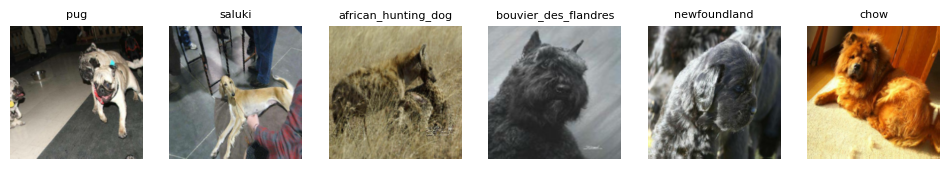

In [4]:
def load(path, y):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.image.resize(img, (IMG, IMG)), y          # raw 0..255 floats

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
])

def make_ds(d, training):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.y.values))
    if training: ds = ds.shuffle(len(d))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE)
    if training: ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)

# preview a few training images
xb, yb = next(iter(train_ds))
plt.figure(figsize=(12, 4))
for i in range(6):
    plt.subplot(1, 6, i + 1); plt.imshow(xb[i].numpy().astype("uint8")); plt.title(class_names[yb[i]], fontsize=8); plt.axis("off")
plt.show()

## 5. Build the model
MobileNetV2 base (ImageNet weights, frozen) → global average pooling → dropout → 120-way softmax.

In [5]:
inp = tf.keras.Input((IMG, IMG, 3))
x = tf.keras.layers.Rescaling(1/127.5, offset=-1)(inp)  # MobileNetV2 expects [-1, 1]
base = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
base.trainable = False
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
out = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
model = tf.keras.Model(inp, out)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │       153,720 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,411,704 (9.20 MB)

 Trainable params: 153,720 (600.47 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Stage 1 — train the classification head (base frozen)

In [6]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cb = [tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)]
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb)

Epoch 1/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 140s 502ms/step - accuracy: 0.5160 - loss: 2.0691 - val_accuracy: 0.7639 - val_loss: 0.8848
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 75s 333ms/step - accuracy: 0.7588 - loss: 0.8245 - val_accuracy: 0.7991 - val_loss: 0.6964
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 75s 335ms/step - accuracy: 0.8119 - loss: 0.6193 - val_accuracy: 0.7939 - val_loss: 0.6664
Epoch 4/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 75s 336ms/step - accuracy: 0.8414 - loss: 0.5174 - val_accuracy: 0.7880 - val_loss: 0.6746
Epoch 5/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 76s 339ms/step - accuracy: 0.8629 - loss: 0.4361 - val_accuracy: 0.8050 - val_loss: 0.6424
Epoch 6/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 75s 333ms/step - accuracy: 0.8709 - loss: 0.4042 - val_accuracy: 0.7945 - val_loss: 0.6374
Epoch 7/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 75s 333ms/step - accuracy: 0.8929 - loss: 0.3435 - val_accuracy: 0.7978 - val_loss: 0.6447
Epoch 8/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 84s 345ms/step - accuracy: 0.9002 - loss: 

## 7. Stage 2 — fine-tune the top 30 layers of MobileNetV2
A much lower learning rate (1e-5) adapts the pre-trained features to dog breeds without destroying them.

In [7]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=cb)

Epoch 1/5
224/224 ━━━━━━━━━━━━━━━━━━━━ 117s 439ms/step - accuracy: 0.8137 - loss: 0.6069 - val_accuracy: 0.8134 - val_loss: 0.6113
Epoch 2/5
224/224 ━━━━━━━━━━━━━━━━━━━━ 79s 352ms/step - accuracy: 0.8500 - loss: 0.4987 - val_accuracy: 0.8095 - val_loss: 0.6134
Epoch 3/5
224/224 ━━━━━━━━━━━━━━━━━━━━ 78s 347ms/step - accuracy: 0.8710 - loss: 0.4386 - val_accuracy: 0.8082 - val_loss: 0.6193
Epoch 4/5
224/224 ━━━━━━━━━━━━━━━━━━━━ 82s 347ms/step - accuracy: 0.8707 - loss: 0.4144 - val_accuracy: 0.8069 - val_loss: 0.6298


## 8. Training curves

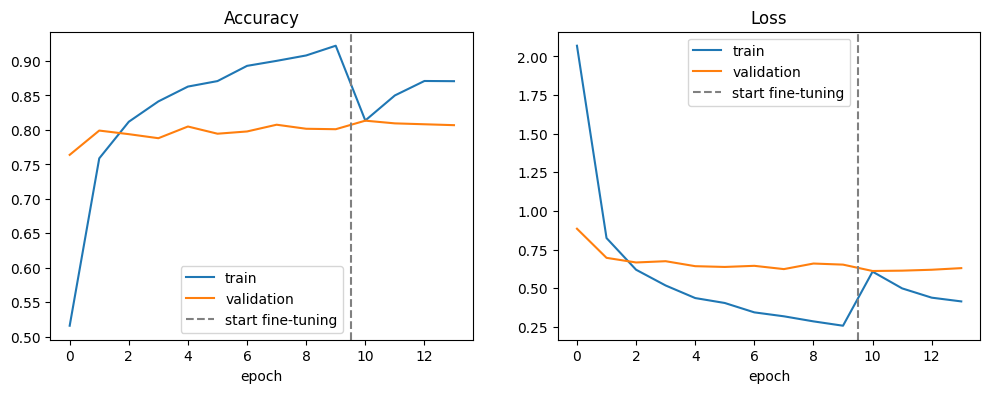

In [8]:
acc = hist1.history["accuracy"] + hist2.history["accuracy"]
val_acc = hist1.history["val_accuracy"] + hist2.history["val_accuracy"]
loss = hist1.history["loss"] + hist2.history["loss"]
val_loss = hist1.history["val_loss"] + hist2.history["val_loss"]
split = len(hist1.history["accuracy"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (tr, va, name) in zip(ax, [(acc, val_acc, "Accuracy"), (loss, val_loss, "Loss")]):
    a.plot(tr, label="train"); a.plot(va, label="validation")
    a.axvline(split - 0.5, color="gray", ls="--", label="start fine-tuning")
    a.set_title(name); a.set_xlabel("epoch"); a.legend()
plt.show()

## 9. Evaluate on the held-out test set

In [9]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
t0 = time.time(); probs = model.predict(test_ds); ms = (time.time() - t0) * 1000 / len(y_true)
y_pred = probs.argmax(1)

report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
metrics = {"model": ARCH, "accuracy": accuracy_score(y_true, y_pred),
           "macro_precision": report["macro avg"]["precision"], "macro_recall": report["macro avg"]["recall"],
           "macro_f1": report["macro avg"]["f1-score"], "inference_ms_per_image": ms}
top5 = np.mean([t in np.argsort(p)[-5:] for t, p in zip(y_true, probs)])
print(json.dumps(metrics, indent=2))
print(f"Top-5 accuracy: {top5:.4f}")
json.dump(metrics, open(f"{ARCH}_metrics.json", "w"), indent=2)

48/48 ━━━━━━━━━━━━━━━━━━━━ 23s 399ms/step
{
  "model": "mobilenet_v2",
  "accuracy": 0.8109517601043025,
  "macro_precision": 0.8216633278976797,
  "macro_recall": 0.8051424015297854,
  "macro_f1": 0.8023766618187002,
  "inference_ms_per_image": 15.036159885908821
}
Top-5 accuracy: 0.9707


### Best and worst breeds

In [10]:
per_breed = pd.DataFrame({b: report[b] for b in class_names}).T.sort_values("f1-score")
print("Hardest breeds:"); display(per_breed.head(10))
print("Easiest breeds:"); display(per_breed.tail(10))

Hardest breeds:


,precision,recall,f1-score,support
eskimo_dog,0.285714,0.200000,0.235294,10.0
siberian_husky,0.500000,0.285714,0.363636,14.0
appenzeller,1.000000,0.272727,0.428571,11.0
walker_hound,0.500000,0.400000,0.444444,10.0
american_staffordshire_terrier,0.428571,0.545455,0.480000,11.0
whippet,0.666667,0.428571,0.521739,14.0
lhasa,0.750000,0.428571,0.545455,14.0
staffordshire_bullterrier,0.600000,0.500000,0.545455,12.0
miniature_poodle,0.833333,0.416667,0.555556,12.0
silky_terrier,0.615385,0.571429,0.592593,14.0


Easiest breeds:


,precision,recall,f1-score,support
keeshond,0.923077,1.0000,0.960000,12.0
groenendael,0.923077,1.0000,0.960000,12.0
dandie_dinmont,0.933333,1.0000,0.965517,14.0
japanese_spaniel,1.000000,0.9375,0.967742,16.0
bedlington_terrier,1.000000,1.0000,1.000000,14.0
african_hunting_dog,1.000000,1.0000,1.000000,13.0
ibizan_hound,1.000000,1.0000,1.000000,14.0
pomeranian,1.000000,1.0000,1.000000,17.0
papillon,1.000000,1.0000,1.000000,15.0
sussex_spaniel,1.000000,1.0000,1.000000,11.0


## 10. Inference engine
This is the same logic the Android app uses:
- returns the **top-5** breeds with confidence scores
- confidence **≥ 80% = High**, **50–80% = Medium**, **< 50% = Low**
- **Low confidence** shows a warning that the photo may be unclear, a mixed breed, or **not a dog**
  (the model is a closed-set classifier and always picks one of the 120 breeds)

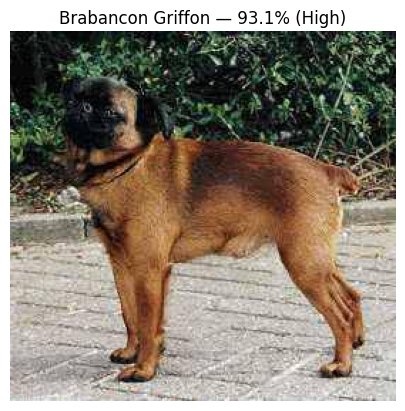

True: Brabancon Griffon
{
  "breed": "Brabancon Griffon",
  "confidence": 0.9314247965812683,
  "level": "High",
  "warning": null,
  "alternatives": [
    [
      "Malinois",
      0.058703962713479996
    ],
    [
      "Border Terrier",
      0.0040996805764734745
    ],
    [
      "Boxer",
      0.002631977666169405
    ],
    [
      "Bull Mastiff",
      0.002005379879847169
    ]
  ],
  "inference_ms": 13577.089071273804
}


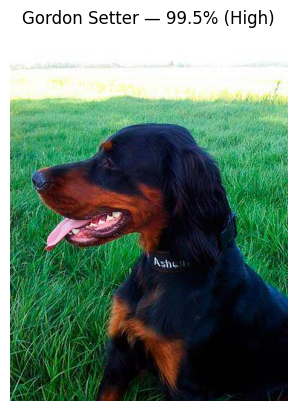

True: Gordon Setter
{
  "breed": "Gordon Setter",
  "confidence": 0.994987428188324,
  "level": "High",
  "warning": null,
  "alternatives": [
    [
      "Rottweiler",
      0.001756238634698093
    ],
    [
      "Bernese Mountain Dog",
      0.0012828204780817032
    ],
    [
      "Irish Setter",
      0.0006990816327743232
    ],
    [
      "Tibetan Mastiff",
      0.00026117952074855566
    ]
  ],
  "inference_ms": 91.13001823425293
}


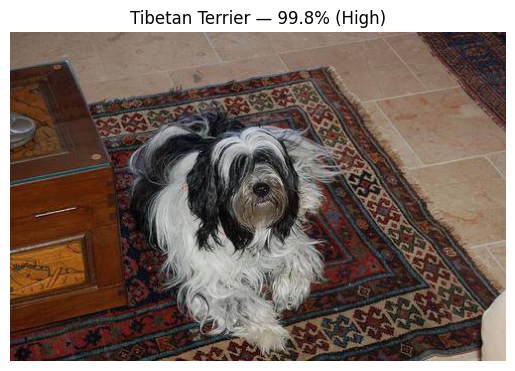

True: Tibetan Terrier
{
  "breed": "Tibetan Terrier",
  "confidence": 0.9978259205818176,
  "level": "High",
  "warning": null,
  "alternatives": [
    [
      "Lhasa",
      0.0009041851735673845
    ],
    [
      "Old English Sheepdog",
      0.0006454378017224371
    ],
    [
      "Shih-tzu",
      0.00025780804571695626
    ],
    [
      "English Setter",
      8.050510223256424e-05
    ]
  ],
  "inference_ms": 94.91729736328125
}


In [11]:
def pretty(label):
    return " ".join(w.capitalize() for w in label.split("_"))

def predict_breed(image_path, top_k=5):
    img = tf.image.resize(tf.io.decode_image(tf.io.read_file(image_path), channels=3, expand_animations=False), (IMG, IMG))
    t0 = time.time(); p = model.predict(img[None, ...], verbose=0)[0]; ms = (time.time() - t0) * 1000
    top = np.argsort(p)[::-1][:top_k]
    best = p[top[0]]
    level = "High" if best >= 0.8 else "Medium" if best >= 0.5 else "Low"
    return {
        "breed": pretty(class_names[top[0]]),
        "confidence": float(best),
        "level": level,
        "warning": None if best >= 0.5 else "Low confidence: unclear photo, mixed breed, or not a dog.",
        "alternatives": [(pretty(class_names[i]), float(p[i])) for i in top[1:]],
        "inference_ms": ms,
    }

# demo on a few test images
for path in test_df.path.values[:3]:
    r = predict_breed(path)
    plt.imshow(plt.imread(path)); plt.axis("off")
    plt.title(f"{r['breed']} — {r['confidence']:.1%} ({r['level']})"); plt.show()
    print("True:", pretty(test_df.set_index("path").breed[path]))
    print(json.dumps(r, indent=2))

## 11. Export to TensorFlow Lite for the Android app

In [12]:
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]   # smaller file, faster on phone
tflite_bytes = conv.convert()
open(f"{ARCH}.tflite", "wb").write(tflite_bytes)
open("labels.txt", "w").write("\n".join(class_names))
print(f"Saved {ARCH}.tflite ({len(tflite_bytes)/1e6:.1f} MB) and labels.txt")

Saved artifact at '/tmp/tmpi1iptw7e'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_4')
Output Type:
  TensorSpec(shape=(None, 120), dtype=tf.float32, name=None)
Captures:
  133351519902928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133351519905232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133351519902736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133351519901200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133351519903120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133351519911760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133351519900432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133351519900624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133351519897552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133351519907152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1333516895

### Check the TFLite model gives the same answers as the Keras model

In [13]:
interp = tf.lite.Interpreter(model_content=tflite_bytes)
interp.allocate_tensors()
inp_d, out_d = interp.get_input_details()[0], interp.get_output_details()[0]

xb, yb = next(iter(test_ds))
agree = 0
for i in range(len(xb)):
    interp.set_tensor(inp_d["index"], xb[i:i+1].numpy().astype(np.float32))
    interp.invoke()
    agree += interp.get_tensor(out_d["index"])[0].argmax() == model.predict(xb[i:i+1], verbose=0)[0].argmax()
print(f"Keras vs TFLite top-1 agreement: {agree}/{len(xb)}")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Keras vs TFLite top-1 agreement: 31/32


## 12. Comparison with the other approaches
All three models were trained with the same data split and evaluated on the same test set.

| Model | Approach | Test accuracy | Macro F1 | ms / image (Colab GPU) | TFLite size |
|---|---|---|---|---|---|
| **MobileNetV2** | Transfer learning + fine-tuning | **79.9%** | **0.794** | 26.7 | 2.7 MB |
| EfficientNet-B0 | Transfer learning + fine-tuning | 79.6% | 0.791 | 22.7 | 4.7 MB |
| Custom CNN | Trained from scratch (baseline) | 6.3% | 0.037 | 6.7 | 0.4 MB |

**Conclusion:** transfer learning is essential with ~60 images per breed. The custom CNN learns from
zero and cannot generalise, while the ImageNet pre-trained models reach ~80%. **MobileNetV2** is chosen as the
final engine: the highest accuracy and F1, and the smallest of the accurate models, which suits on-device use.

**Known limitation:** the model is a closed-set classifier, so a non-dog image (e.g. a cat) still gets a breed.
The low-confidence warning reduces this; a future improvement is an out-of-distribution "is this a dog?" check
before classification.

## 13. Download the outputs

In [14]:
files.download(f"{ARCH}.tflite")
files.download("labels.txt")
files.download(f"{ARCH}_metrics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>